# 04 — Interpreting the final model (SHAP)

`shap.TreeExplainer` on 2,000 random rows from `test_in`. SHAP values of the one-hot columns and of
the sin/cos pairs are **summed back to the original features** (SHAP values are additive), so e.g.
`County` is one entry instead of dozens.

SHAP describes how the model works, not what causes accidents. The top position of `Source` means
that the model largely learns how each data provider assigns labels.

In [1]:
import sys, warnings
sys.path.append('..')
warnings.filterwarnings('ignore')
import pandas as pd
pd.set_option('display.precision', 3)
import joblib
from src.experiment import load_all, RESULTS_DIR
from src.final import FINAL_MODEL_PATH
from src.explain import shap_values_by_feature, importance_table
from src import plots

df = load_all()
sample = df[df['split'] == 'test_in'].sample(n=2000, random_state=42)
model = joblib.load(FINAL_MODEL_PATH)
shap_by_class = shap_values_by_feature(model, sample)
importance = importance_table(shap_by_class)
importance.to_csv(f'{RESULTS_DIR}/shap_importance.csv')
importance.head(15)

,Sev1-2,Sev3,Sev4,mean_all_classes
Source,0.422,1.019,1.507,0.983
road_type,0.289,0.425,0.150,0.288
Wind_Speed(mph),0.257,0.350,0.102,0.237
Start_Lng,0.189,0.249,0.136,0.192
Month,0.148,0.221,0.139,0.169
Start_Lat,0.139,0.192,0.152,0.161
Hour,0.061,0.083,0.213,0.119
Pressure(in),0.094,0.123,0.132,0.116
Wind_Direction_Mapped,0.089,0.087,0.068,0.081
County,0.084,0.089,0.064,0.079


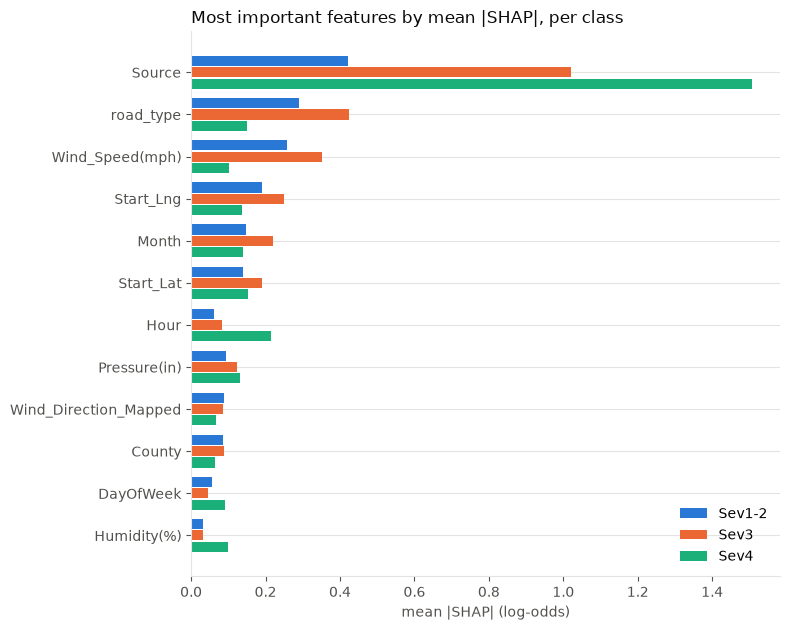

In [2]:
fig = plots.importance_by_class(importance, top=12, title='Most important features by mean |SHAP|, per class')

**Note on interpretation.** `Wind_Speed(mph)` is missing in 9.4% of rows, and how often it is
missing may depend on the period and the weather station. Its high position may therefore partly
reflect time or data source rather than an effect of wind. This is a hypothesis to check, not a conclusion.